In [22]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

In [23]:
vqls = oasis_dla.VQLS(qubits=1, cost='direct')

A = np.array([
    [1, 0],
    [0, 1]
])

b = (1/np.sqrt(2)) * np.array([
    [1],
    [1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(f"Quantum Soln: \n{solution.solution()}")
print(f"Classical Soln: \n{np.linalg.solve(A, b)}")

solution.get_probabilities()

Training time: 0.07403650000924245
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.571e+00]
     nit: 32
   maxcv: 0.0
    nfev: 17
Quantum Soln: 
[[0.70710678+0.j]
 [0.70710678+0.j]]
Classical Soln: 
[[0.70710678]
 [0.70710678]]


{'1': 0.5051, '0': 0.4949}

Training time: 0.12295829999493435
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.571e+00]
     nit: 36
   maxcv: 0.0
    nfev: 18
Training time: 0.09278600005200133
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.571e+00]
     nit: 31
   maxcv: 0.0
    nfev: 17
Training time: 0.07039040001109242
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.571e+00]
     nit: 29
   maxcv: 0.0
    nfev: 18
Training time: 0.0577976000495255
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 1.571e+00]
     nit: 32
   maxcv: 0.0
    nfev: 17
Training time: 0.06634009996196255
 message: The lower bound for the trust-region rad

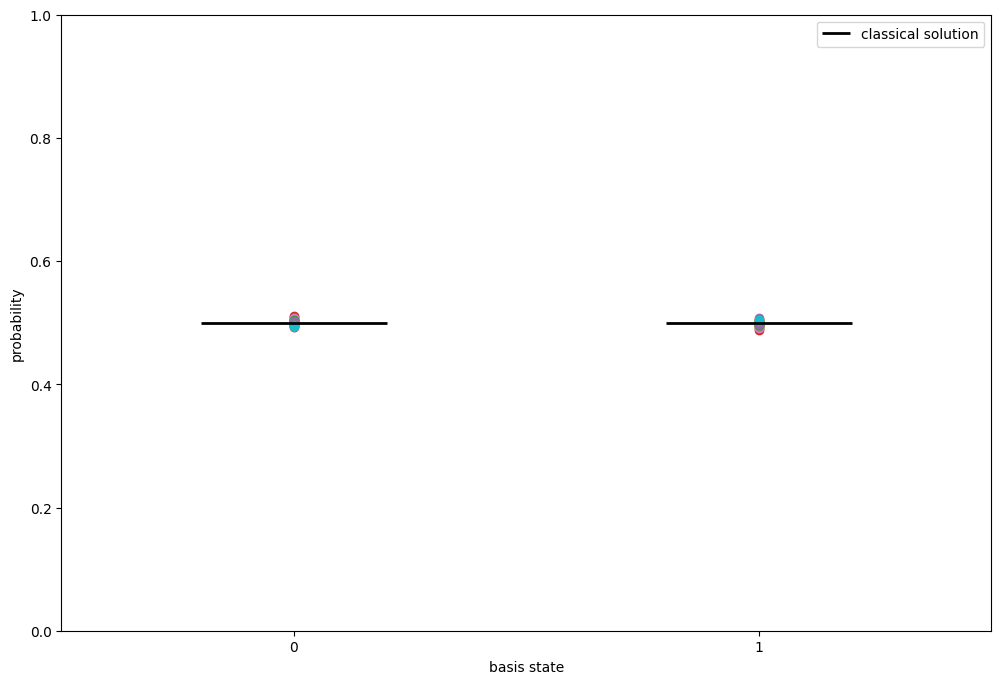

In [24]:
tests = 30

prob_list = []
for i in range(0, tests):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

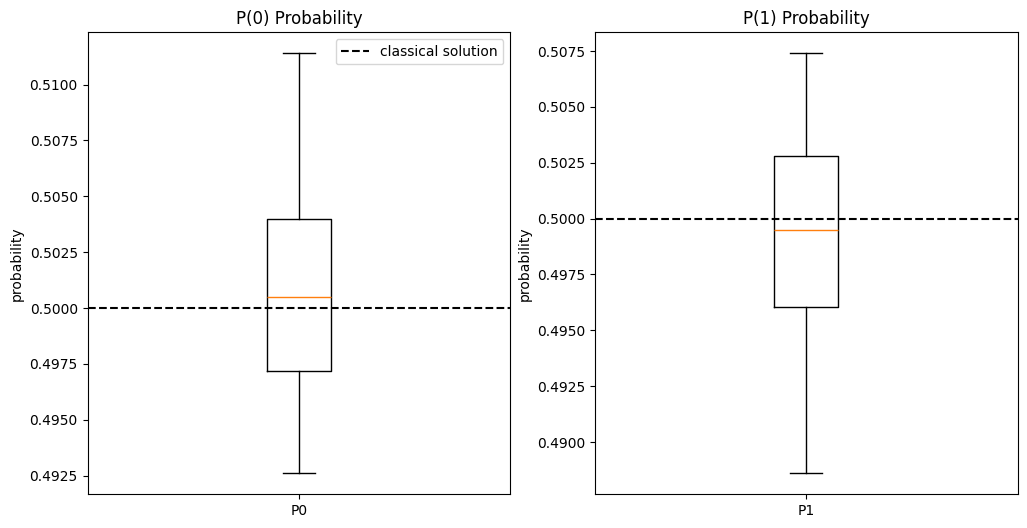

In [25]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panel
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
# plt.tight_layout()
axes[0].set_title("P(0) Probability")
axes[1].set_title("P(1) Probability")
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [26]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [random_c(), random_c()],
    [random_c(), random_c()]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])

print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# difference as a metric of accuracy
print(f"Accuracy: {vqls.compute_accuracy(qres, cres)*100:.3f}%")

[[0.13323834+0.10672442j 0.53465021+0.18532831j]
 [0.57671165+0.92159649j 0.02265296+0.51993824j]]
Training time: 0.08769129996653646
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.21386743713475198
       x: [ 2.068e+00]
     nit: 38
   maxcv: 0.0
    nfev: 19
Quantum Solution: 
[[0.27124584-0.36465573j]
 [0.455909  -0.612912j  ]]

Classical Solution: 
[[-0.17825921-0.74994075j]
 [ 1.15555398-0.17808166j]]

Accuracy: -1.444%


In [27]:
# def res_diff(x, y):
#     return 1 - np.linalg.norm(x-y)

# def test_vqls(b=None, shots=30):
#     Ai = [ # random data set of matrices
#         np.array([
#             [1, random_c()],
#             [random_c(), random_c()]
#         ]) for _ in range(shots)
#     ]

#     if b is None:
#         b = 1/np.sqrt(2) * np.array([
#             [1],
#             [1]
#         ])

#     accuracies = []
#     for A in Ai:
#         # print(b)
#         q_soln = vqls.solve(A, b).solution()
#         c_soln = np.linalg.solve(A, b)
#         # print(f"Quantum Solution: \n{q_soln}\n")
#         # print(f"Classical Solution: \n{c_soln}\n")

#         diff = res_diff(q_soln, c_soln)
#         # print(f"Accuracy: {diff}")
#         accuracies.append(diff)

#     # print(accuracies)

#     return accuracies

# accuracies = test_vqls()
# avg_diff = sum(accuracies) / len(accuracies)

# print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

In [28]:
# avg_diff, accuracies

In [29]:
# plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
# plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
# plt.ylabel("Accuracy")
# plt.xlabel("Test # (random matrix)")
# plt.title("Constant Top Right Entry")
# plt.legend()

In [30]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

data = vqls.generate_dataset(random_entries=[1+1j, 2+1j, 3+1j, 4+1j], shots=100)
print(data[:3])

# 1 param ansatz ry h
accuracies_ry, t_times_ry = vqls_ry.accuracy_test(data)
accuracies_rz, t_times_rz = vqls_rz.accuracy_test(data)

[array([[0.24958972+0.62901731j, 0.64897735+0.31447308j],
       [0.56480942+0.60928058j, 0.23150444+0.79593036j]]), array([[0.83075882+0.73044745j, 0.34039015+0.26258745j],
       [0.07088581+0.30099112j, 0.23190936+0.86566888j]]), array([[0.25039282+0.05189997j, 0.91435295+0.8164459j ],
       [0.51383678+0.42383579j, 0.12097222+0.41074924j]])]
Training time: 0.12323700002161786
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.012096744555682881
       x: [ 8.240e-01]
     nit: 37
   maxcv: 0.0
    nfev: 19
0.7566240073137201
Training time: 0.12958740000613034
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.09256578911460989
       x: [ 2.046e+00]
     nit: 40
   maxcv: 0.0
    nfev: 20
0.5128787410812772
Training time: 0.06985339999664575
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.016094132657688

Average Accuracy = 0.24394630492888317
Average Accuracy = 0.9999994990037583


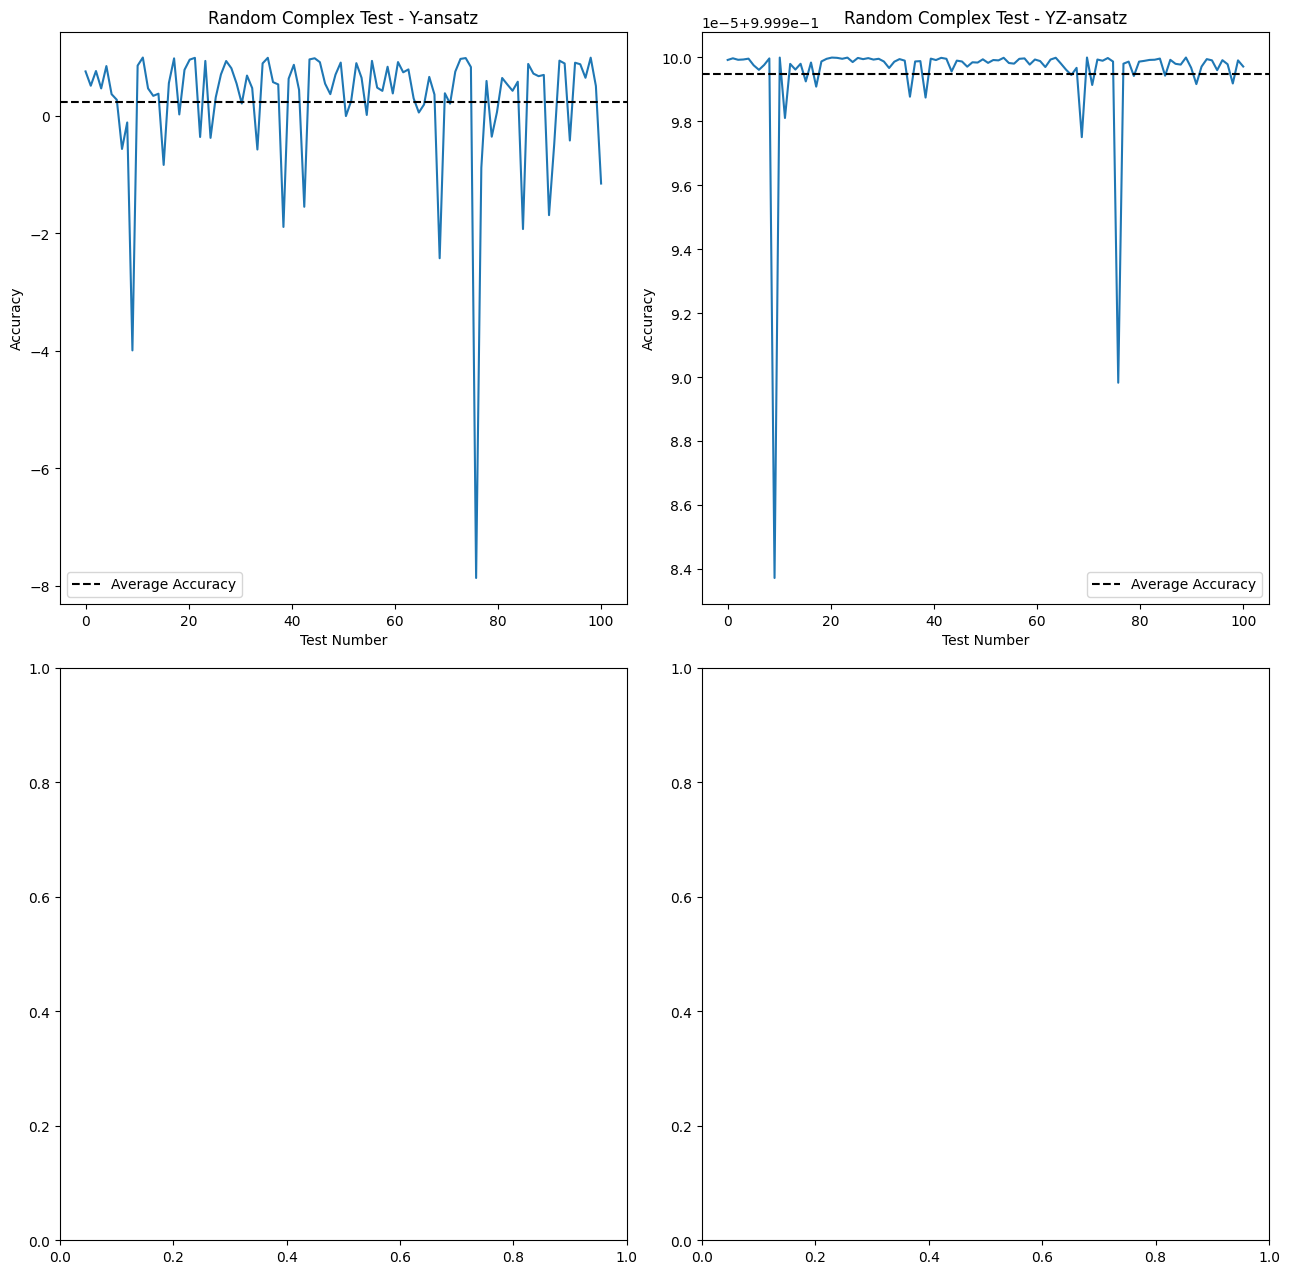

[0.07199250004487112]

In [31]:
# 2 param ansatz rz ry h
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(13, 13), sharey=False)
ax_0 = vqls_ry.plot_tests(accuracies_ry, title="Random Complex Test - Y-ansatz", ax=axes[0, 0])
ax_1 = vqls_rz.plot_tests(accuracies_rz, title="Random Complex Test - YZ-ansatz", ax=axes[0, 1])

plt.tight_layout()
plt.show()

t_times_ry